In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from pcg_denoising import config
import pcg_denoising.utils.visualization as vis
from pcg_denoising.splits import load_folds

plt.rcParams["font.family"] = "Times New Roman"

c:\Users\ASUS\Desktop\Doctorado\CICESE\Projects\PCG-Denoising\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
fold_idx = 0
pathology = "AS"
noise_type = "Speech"
noise_level = -5
n = 0

save_figs = True

In [3]:
root = Path.cwd().parent
cfg = config.load_config(root / "config" / "config.toml", override_path=root / "config" / "vis.toml")
sr = cfg.audio.sr

signal = vis.pick_signal(cfg, fold_idx, pathology, n)
case = vis.locate(cfg, signal, noise_type, noise_level, fold_idx=fold_idx)
name = case.pathology_name

print(f"Fold: {fold_idx}\nNoise Type: {noise_type}\nNoise level: {noise_level} dB\nPathology: {name}\nSignal: {signal}")

Fold: 0
Noise Type: Speech
Noise level: -5 dB
Pathology: aortic stenosis
Signal: AS_New_3/New_AS_001.wav


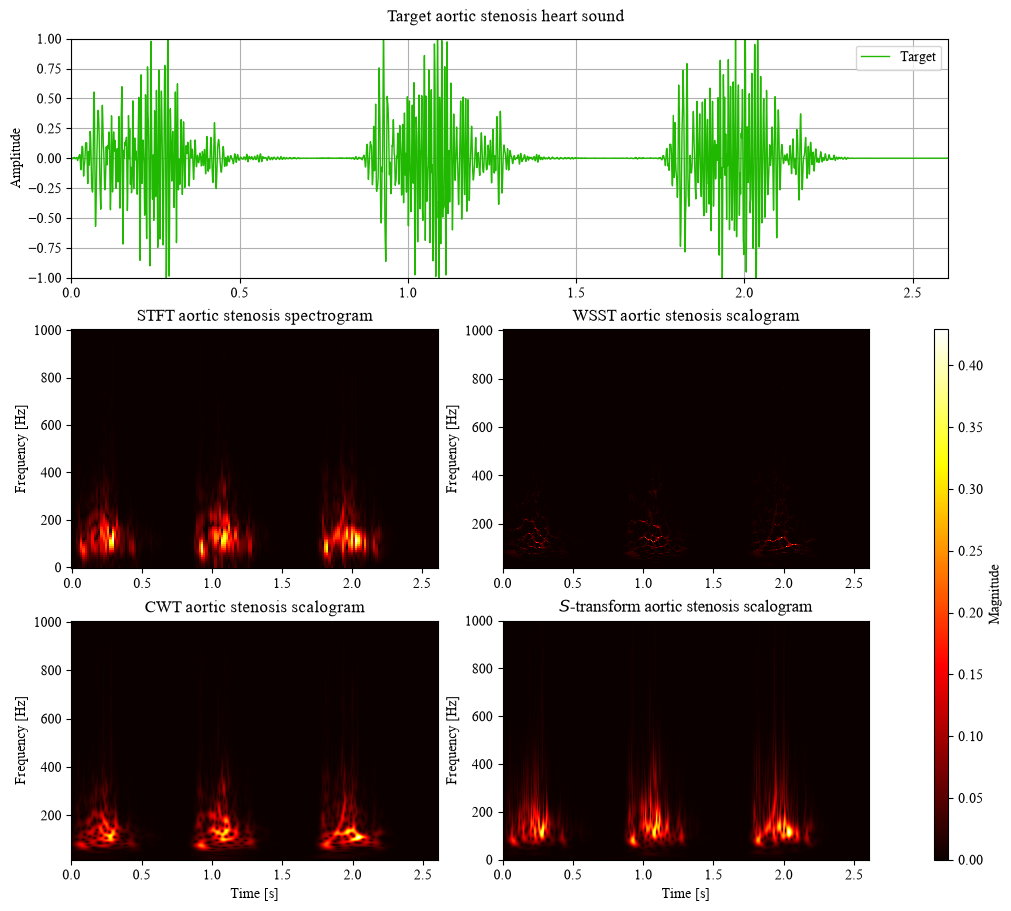

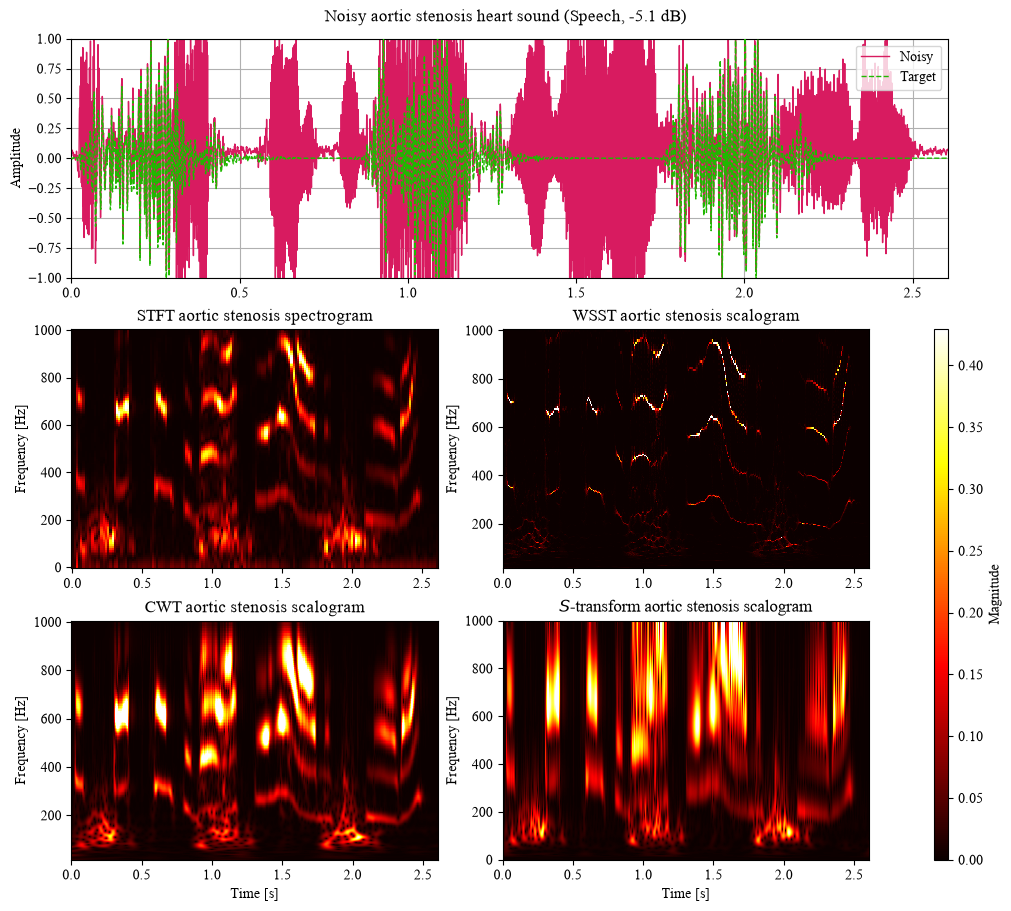

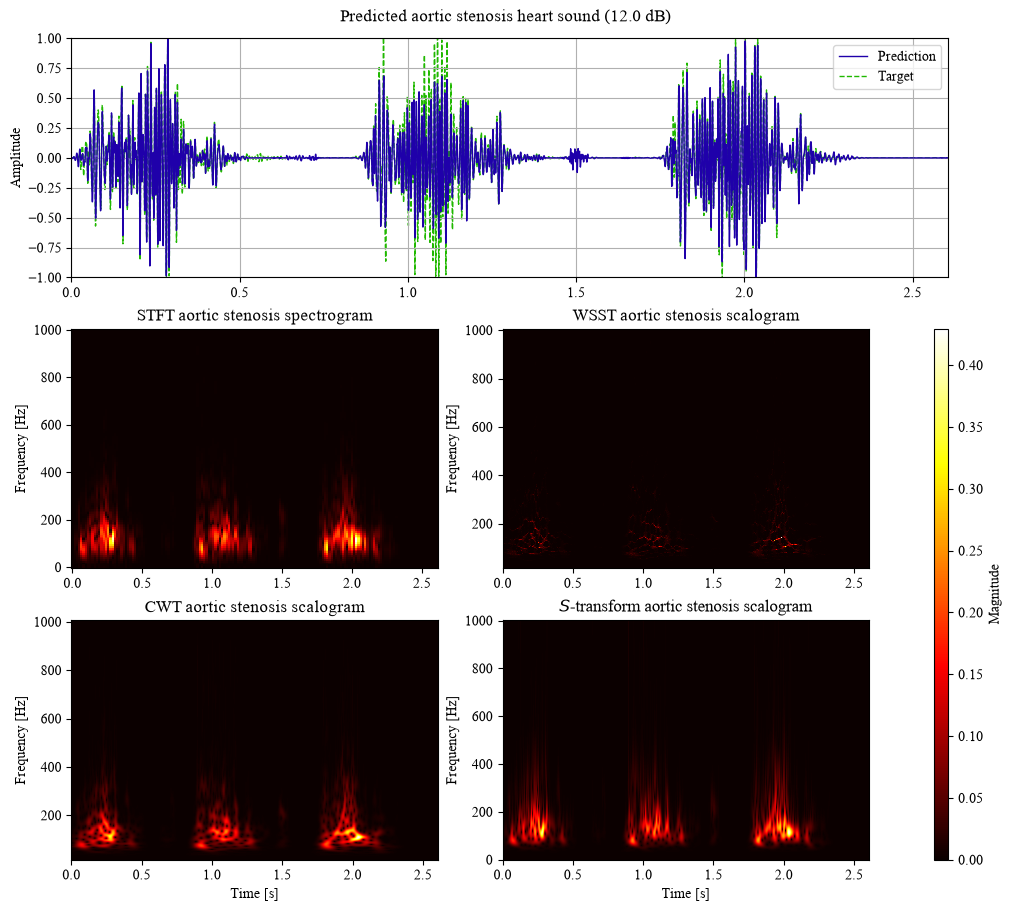

In [4]:
x = {k: vis.load_signal(getattr(case, k), sr) for k in ("target", "noisy", "prediction")}
imgs = {k: vis.tf_images(v, sr, cfg, scale="linear") for k, v in x.items()}
limits = vis.color_limits(imgs["target"])
amp = np.abs(x["noisy"]).max()
ylim = (-amp, amp)

stem = f"{cfg.experiment.experiment_name}_{Path(signal).stem}_{noise_type}_{noise_level}dB"
figs = {
    "target": vis.plot_signal(x["target"], sr, imgs["target"], limits,
                              f"Target {name} heart sound", name, ylim, color=vis.COLORS["target"]),
    "noisy": vis.plot_signal(x["noisy"], sr, imgs["noisy"], limits,
                             f"Noisy {name} heart sound ({case.kind}, {case.sisdr_noisy:.1f} dB)", name, ylim,
                             color=vis.COLORS["noisy"], label="Noisy", target=x["target"], target_front=True),
    "prediction": vis.plot_signal(x["prediction"], sr, imgs["prediction"], limits,
                                  f"Predicted {name} heart sound ({case.sisdr:.1f} dB)", name, ylim,
                                  color=vis.COLORS["prediction"], label="Prediction", target=x["target"]),
}
if save_figs:
    for key, fig in figs.items():
        vis.save_svg(fig, f"{stem}_{key}")

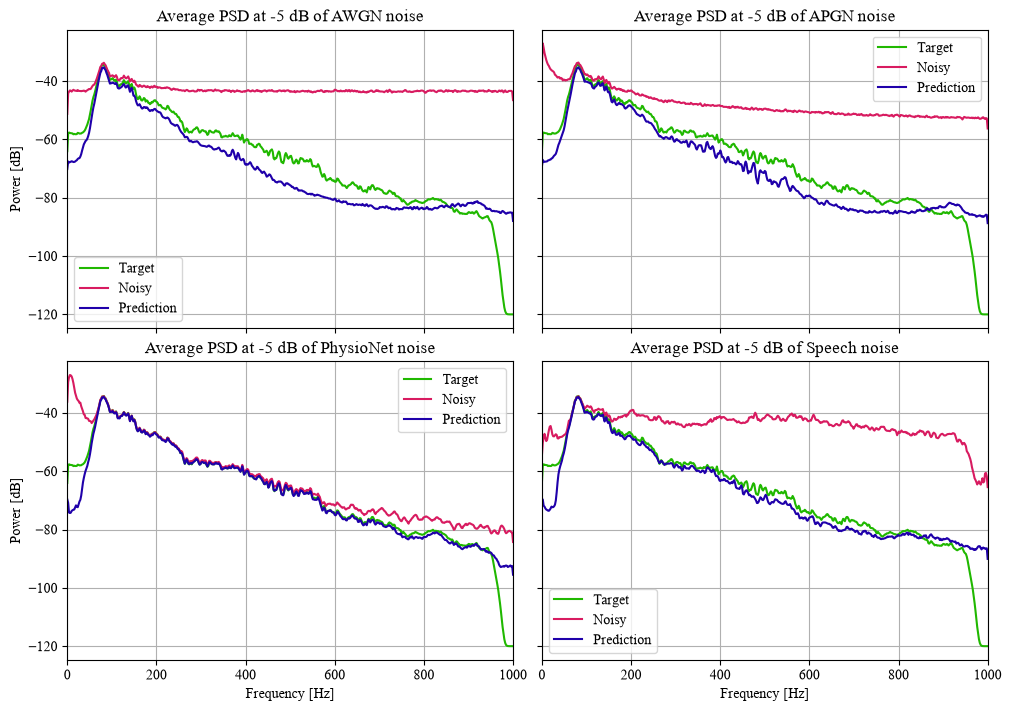

In [5]:
fig = vis.plot_psd(cfg, noise_level, fold_idx=fold_idx, nperseg=1024)

if save_figs:
    vis.save_svg(fig, f"{cfg.experiment.experiment_name}_psd_{noise_level}dB")